# Del notebook al microservicio · Parte 1: el modelo de Randuin

**ITY1102 · Arquitectura de Sistemas de IA · Equipo 7** — Caso 3: *Kipu Pagos SpA* · detección de fraude en pagos digitales (**Randuin**)

> **El caso.** Kipu Pagos evalúa cada transacción de su billetera y de la pasarela de comercios *antes* de autorizarla. El motor de reglas heredado bloqueó en 2025 a 460 clientes legítimos por día y dejó pasar cerca de USD 500.000 en fraude (EP1, 1.1). Randuin combina las reglas normativas con un modelo de aprendizaje automático que devuelve la probabilidad de fraude de cada transacción.

| Concepto | Valor |
|---|---|
| Fraude no detectado | **el monto de la transacción** (pérdida directa), en USD |
| Revisión de una alerta (verdadera o falsa) | **USD 5** ← *supuesto del equipo.|
| Lo que pide Riesgo (EP1, 1.3) | *Bajar los falsos positivos sin subir el fraude, y cambiar umbrales sin pedirle nada a ingeniería.* |

### Ruta del notebook
1. Cargar los datos crudos
2. Perfilar (filas, tipos, nulos, duplicados)
3. Limpiar con reglas escritas e integrar las cuatro tablas
4. Variables de entrada y separación entrenamiento / validación / prueba
5. Línea base «tonta» y por qué la exactitud engaña
6. Línea base clásica con scikit-learn
7. Evaluar con métricas que importan al negocio
8. **Red neuronal con TensorFlow / Keras**
9. **Exportar a ONNX** y verificar con `onnxruntime`
10. Mejorar la red y compararla con árboles
11. Anexo: del notebook al script, supuestos y checklist

### Entrenar con TensorFlow, servir con ONNX

Se entrena con **TensorFlow/Keras**, pero lo que llega a la imagen Docker no es el framework: es el modelo exportado a **ONNX**, un formato estándar que ejecuta `onnxruntime`.

**Reglas para la imagen de IA**
1. Sin CUDA ni librerías de GPU: el computador de la defensa no tiene GPU.
2. TensorFlow **no va en la imagen**: se usa en el notebook y en el job de CI.
3. La imagen sirve el modelo con `onnxruntime` y respeta el límite de tamaño del enunciado.

**Decisión de arquitectura**: se entrena con la herramienta más cómoda y se sirve con el runtime más liviano.

> **Librerías necesarias:** `pip install pandas scikit-learn joblib matplotlib tensorflow tf2onnx onnx onnxruntime`. En Google Colab ya vienen pandas, scikit-learn y TensorFlow; basta `%pip install -q tf2onnx onnx onnxruntime`.

## 0 · Preparación

In [ ]:
import json
import os
import re
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

try:
    from IPython.display import display
except ImportError:                      # al ejecutar como script (preparar.py / entrenar.py)
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

FRAMEWORK = "tensorflow"       # decisión del equipo: se entrena con TensorFlow/Keras y se sirve con ONNX
SEMILLA = 42                   # reproducibilidad: mismo resultado en cualquier computador

# --- Rutas (cada una se puede cambiar con una variable de entorno) ---
RAIZ = Path.cwd()
if not (RAIZ / "datos").exists() and (RAIZ.parent / "datos").exists():
    RAIZ = RAIZ.parent                                             # el notebook vive en una subcarpeta

def _buscar_datos() -> Path:
    candidatos = [os.environ.get("DATA_DIR"), RAIZ / "datos" / "raws", RAIZ / "datos", Path.cwd()]
    for c in candidatos:
        if c and (Path(c) / "transacciones.csv").exists():
            return Path(c)
    raise FileNotFoundError("No encuentro los CSV: pon usuarios.csv, dispositivos.csv, lista_negra.csv y "
                            "transacciones.csv en datos/raws/ (o define DATA_DIR)")

RUTA_DATOS = _buscar_datos()
RUTA_TRATADOS = Path(os.environ.get("OUT_DIR", RAIZ / "datos" / "tratados"))        # los usa el servicio carga-datos
RUTA_MODELO = Path(os.environ.get("MODEL_DIR", RAIZ / "servicio-ia" / "model"))      # la API carga el modelo desde aquí
RUTA_TRATADOS.mkdir(parents=True, exist_ok=True)

# --- Supuestos del caso (cambiarlos aquí cambia todo el notebook) ---
TZ_CHILE = "America/Santiago"   # zona a la que se asumen las fechas sin zona horaria
USD_CLP = 950                   # tipo de cambio fijo para llevar USD a CLP
COSTO_REVISION_USD = 5          # costo de cada alerta (revisión manual o fricción con el cliente)

print(f"Framework elegido: {FRAMEWORK}")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Datos crudos en:", RUTA_DATOS)

Framework elegido: tensorflow
scikit-learn 1.9.1 | pandas 2.3.3 | numpy 2.3.5
Datos crudos en: c:\Users\maxer\OneDrive\Desktop\randuin\datos\raws


In [ ]:
# Registro de reglas de limpieza y de perfilado: de aquí salen las cifras del capítulo 8.4 del arc42
reglas, perfiles = [], []

def anotar_regla(tabla, problema, regla, filas):
    reglas.append({"tabla": tabla, "problema": problema, "regla": regla, "filas_afectadas": int(filas)})

def perfilar(df: pd.DataFrame, tabla: str, etapa: str) -> pd.DataFrame:
    perfiles.append({"tabla": tabla, "etapa": etapa, "filas": len(df), "columnas": df.shape[1],
                     "celdas_nulas": int(df.isna().sum().sum()), "filas_duplicadas": int(df.duplicated().sum())})
    print(f"{etapa.upper()} · {tabla}: {df.shape[0]:,} filas × {df.shape[1]} columnas | duplicados exactos: {df.duplicated().sum()}")
    return pd.DataFrame({"nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2), "únicos": df.nunique()})

## 1 · Cargar los datos crudos

Se leen **como texto** (`dtype=str`): así se ven los formatos tal como llegan, antes de decidir cómo corregirlos.

In [ ]:
usuarios_raw     = pd.read_csv(RUTA_DATOS / "usuarios.csv",      dtype=str)
dispositivos_raw = pd.read_csv(RUTA_DATOS / "dispositivos.csv",  dtype=str)
lista_negra_raw  = pd.read_csv(RUTA_DATOS / "lista_negra.csv",   dtype=str)
transacc_raw     = pd.read_csv(RUTA_DATOS / "transacciones.csv", dtype=str)

crudas = {"usuarios": usuarios_raw, "dispositivos": dispositivos_raw,
          "lista_negra": lista_negra_raw, "transacciones": transacc_raw}
transacc_raw.head()

,transaccion_id,usuario_id,comercio_id,dispositivo_id,timestamp,monto,moneda,canal,mcc,pais_transaccion,latitud,longitud,ip,tarjeta_enmascarada,resultado_autorizacion,intentos_previos_1h,revisado_por_analista,motivo_bloqueo,es_fraude
0,TX7002858,KP300267,CM40847,D-1358e431cbe4,2026-01-12T14:48:02Z,$9,USD,app,6011,CL,-43.59876,-68.42320,72.152.180.159,****8903,aprobada,0,NaN,NaN,NaN
1,TX7016632,KP304739,CM40774,D-3f1ee74c63b4,2025-10-23 18:24:22,261293,CLP,web,5732,CL,-21.62863,-69.21598,87.124.209.217,****4375,aprobada,1,NaN,NaN,NaN
2,TX7020767,KP300833,CM40011,D-1c2cf1fb719f,2024-01-19T01:36:58Z,2284,CLP,app,5411,cl,-28.17504,-72.37926,215.167.29.26,****2909,rechazada,2,NaN,NaN,NaN
3,TX7008653,KP301367,CM40143,D-2465ac406cf6,2024-09-11T10:26:05Z,3653,CLP,app,4900,CHILE,-32.72609,-70.69970,187.8.49.24,****6900,aprobada,0,NaN,NaN,NaN
4,TX7022002,KP302176,CM40184,D-0ba4944da5cf,2024-11-19 23:33:30,$37,USD,web,7995,CL,-22.77966,-70.87192,219.235.138.63,****2759,aprobada,0,NaN,NaN,NaN


## 2 · Perfilado

Antes de tocar un dato, se mide. Estas cifras van al capítulo **8.4 Datos** del arc42 (*«perfilado antes y después»*).

In [ ]:
perfil_antes = {nombre: perfilar(df, nombre, "antes") for nombre, df in crudas.items()}
perfil_antes["transacciones"]

ANTES · usuarios: 5,038 filas × 10 columnas | duplicados exactos: 38
ANTES · dispositivos: 7,000 filas × 7 columnas | duplicados exactos: 0
ANTES · lista_negra: 350 filas × 7 columnas | duplicados exactos: 0
ANTES · transacciones: 28,421 filas × 19 columnas | duplicados exactos: 97


,nulos,% nulos,únicos
transaccion_id,0,0.00,28324
usuario_id,0,0.00,5582
comercio_id,1616,5.69,1575
dispositivo_id,2533,8.91,6806
timestamp,0,0.00,28316
monto,0,0.00,21112
moneda,1166,4.10,2
canal,0,0.00,14
mcc,0,0.00,12
pais_transaccion,0,0.00,31


In [ ]:
# Las categorías: ¿cuántas formas distintas de escribir lo mismo?
for tabla, col in [("transacciones", "canal"), ("transacciones", "pais_transaccion"),
                   ("usuarios", "segmento"), ("dispositivos", "tipo"), ("lista_negra", "tipo")]:
    print(f"{tabla}.{col}:", crudas[tabla][col].value_counts(dropna=False).to_dict(), "\n")

transacciones.canal: {'app': 9279, 'web': 6306, 'pos': 4143, 'api': 1272, 'APP': 1128, 'Web': 1114, 'WEB': 1102, 'movil': 1093, 'App': 1026, 'POS': 540, 'punto_venta': 510, 'Pos': 473, 'API': 248, 'Api': 187} 

transacciones.pais_transaccion: {'CL': 14524, 'chile ': 1184, 'Chile': 1175, ' CL': 1140, 'CHILE': 1136, 'PE': 1129, 'AR': 1124, 'cl': 1110, 'BR': 914, 'CO': 732, 'US': 731, 'VE': 572, 'RU': 358, 'NG': 335, 'ARGENTINA': 224, 'Venezuela': 218, 'Argentina': 214, 'Perú': 146, 'PERU': 142, 'COLOMBIA': 142, 'Peru': 138, 'Nigeria': 121, 'USA': 118, 'Colombia': 117, 'Brasil': 117, 'Brazil': 114, 'BRASIL': 106, 'Estados Unidos': 105, 'EEUU': 92, 'Russia': 78, 'Rusia': 65} 

usuarios.segmento: {'persona': 2920, 'comercio_pequeno': 467, 'individuo': 426, 'Persona': 419, 'PERSONA': 400, 'comercio_grande': 134, 'pyme': 72, 'COMERCIO_PEQUENO': 72, 'comercio pequeño': 71, 'comercio grande': 22, 'COMERCIO_GRANDE': 19, 'empresa': 16} 

dispositivos.tipo: {'android': 2452, 'ios': 1525, 'web': 10

In [ ]:
# Formatos de fecha y de monto: ¿cuántas formas distintas conviven?
def patron(s):
    return s.dropna().str.replace(r"\d", "d", regex=True).str.replace(r"[A-Za-z]+", "a", regex=True)

print("timestamp:", patron(transacc_raw["timestamp"]).value_counts().to_dict(), "\n")
print("monto (formas más comunes):", patron(transacc_raw["monto"]).value_counts().head(8).to_dict())

timestamp: {'a-a-a a:a:a': 13156, 'a-a-a:a:a': 7434, 'a-a-a a:a:a-a:a': 4464, 'a/a/a a:a': 3367} 

monto (formas más comunes): {'a': 18761, 'a.a': 6365, '$a.a': 2435, '$a': 347, 'a,a': 263, '-a': 250}


**Lo que encontramos**:

- Filas duplicadas en `transacciones` (97) y en `usuarios` (38): copias exactas.
- Categorías escritas de varias formas: `canal`, país, `segmento`, `tipo` de dispositivo y de lista negra.
- Fechas en cuatro formatos y husos horarios; montos en CLP y USD con `$`, coma y punto.
- Valores imposibles: `nivel_kyc = -1`, `edad_cuenta_dias` negativa, montos negativos, coordenadas (0,0), IP inválidas.
- **`es_fraude` vacío en el 96 % de las transacciones** (nunca fueron revisadas) y **dos columnas que filtran la respuesta** (`revisado_por_analista`, `motivo_bloqueo`).
- Transacciones cuyo usuario no existe en `usuarios` (608) o sin dispositivo (2.526).

## 3 · Limpieza con reglas escritas


| Regla | Problema | Decisión | Por qué |
|---|---|---|---|
| Duplicados | Copias exactas por `transaccion_id` y `usuario_id` | Descartar | Es la misma fila dos veces; inflaría el entrenamiento |
| Categorías | `chile `, `Perú`, `movil`, `pyme`… | Corregir | Es lo mismo escrito distinto; se normaliza a un código |
| Fechas | Cuatro formatos y husos | Corregir | Todo a UTC (sin zona = hora de Chile) |
| Montos | `$`, coma o punto, CLP y USD | Corregir | El punto es miles en CLP y decimal en USD: se interpreta según la moneda |
| Fuera de rango | `nivel_kyc = -1`, edad negativa, coordenadas (0,0) | Marcar como nulo o con bandera | El resto de la fila sirve |
| Etiqueta vacía | `es_fraude` sin valor = **no revisada** | Excluir del entrenamiento | No significa «legítima»: sin etiqueta no se puede entrenar ni evaluar |
| Fuga de información | `revisado_por_analista`, `motivo_bloqueo` | Excluir del modelo | Solo existen **después** de revisar la transacción |
| Dato personal | `tarjeta_enmascarada`, `ip` | No usar ni guardar | RNF5 y capítulo 8.3 |

### 3.1 Funciones de apoyo

In [ ]:
PAISES = {
    "CHILE": "CL", "ARGENTINA": "AR", "PERU": "PE", "PERÚ": "PE", "COLOMBIA": "CO",
    "BRASIL": "BR", "BRAZIL": "BR", "VENEZUELA": "VE", "USA": "US", "EEUU": "US",
    "ESTADOS UNIDOS": "US", "RUSIA": "RU", "RUSSIA": "RU", "NIGERIA": "NG",
}

def norm_pais(s):
    """'chile ', ' CL', 'Perú', 'EEUU'... -> código ISO2 en mayúscula."""
    s = s.astype("string").str.strip().str.upper()
    return s.map(lambda v: PAISES.get(v, v) if pd.notna(v) else v).astype("string")

def parse_fecha_simple(s):
    """Fechas sin hora en tres formatos: dd/mm/aaaa, dd-mm-aaaa y aaaa-mm-dd."""
    s = s.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for formato, patron in [("%d/%m/%Y", r"^\d{2}/\d{2}/\d{4}$"),
                            ("%d-%m-%Y", r"^\d{2}-\d{2}-\d{4}$"),
                            ("%Y-%m-%d", r"^\d{4}-\d{2}-\d{2}$")]:
        m = s.str.match(patron).fillna(False).astype(bool)
        if m.any():
            out[m] = pd.to_datetime(s[m], format=formato)
    return out

def parse_ts(s):
    """Fecha y hora a UTC. Cuatro formatos conviven en los datos:
       - 2026-01-12T14:48:02Z         -> ya está en UTC
       - 2026-03-07 06:33:51-04:00    -> trae su desfase, se convierte a UTC
       - 2025-10-23 18:24:22          -> sin zona: se asume hora de Chile
       - 22/11/2024 20:53             -> día/mes/año sin zona: se asume hora de Chile
       En la hora repetida por el cambio de horario se toma la primera ocurrencia."""
    s = s.astype("string").str.strip()
    m_z     = s.str.endswith("Z").fillna(False).astype(bool)
    m_off   = s.str.contains(r"[+-]\d\d:\d\d$").fillna(False).astype(bool)
    m_slash = s.str.contains("/").fillna(False).astype(bool)
    m_iso   = s.notna().to_numpy() & ~(m_z | m_off | m_slash).to_numpy()
    partes = []
    if m_z.any():
        partes.append(pd.to_datetime(s[m_z], utc=True, format="%Y-%m-%dT%H:%M:%SZ"))
    if m_off.any():
        partes.append(pd.to_datetime(s[m_off], utc=True, format="%Y-%m-%d %H:%M:%S%z"))
    for mask, formato in [(m_iso, "%Y-%m-%d %H:%M:%S"), (m_slash, "%d/%m/%Y %H:%M")]:
        if mask.any():
            local = pd.to_datetime(s[mask], format=formato)
            partes.append(local.dt.tz_localize(TZ_CHILE, ambiguous=np.ones(len(local), dtype=bool), nonexistent="shift_forward")
                               .dt.tz_convert("UTC"))
    out = pd.concat(partes).reindex(s.index)
    return out.astype("datetime64[ns, UTC]")

def a_binario(s):
    """'1', 'si', 'SI', 'TRUE' -> 1 ; '0', 'no' -> 0 ; vacío -> NaN."""
    mapa = {"1": 1, "si": 1, "sí": 1, "true": 1, "0": 0, "no": 0, "false": 0}
    return s.astype("string").str.strip().str.lower().map(mapa).astype("float")

### 3.2 Usuarios

In [ ]:
u = usuarios_raw.copy()

# U1. Filas repetidas: son copias exactas -> se descartan
n = u.duplicated().sum()
u = u.drop_duplicates().reset_index(drop=True)
anotar_regla("usuarios", "Filas duplicadas (copias exactas)", "Descartar la copia, queda una por usuario_id", n)
assert u["usuario_id"].is_unique

# U2. País escrito de muchas formas
n = (u["pais"].astype("string").str.strip() != norm_pais(u["pais"])).sum()
u["pais"] = norm_pais(u["pais"])
anotar_regla("usuarios", "País con mayúsculas, espacios y nombres completos", "Corregir a código ISO2", n)

# U3. Segmento con sinónimos
seg = {"persona": "persona", "individuo": "persona",
       "comercio_pequeno": "comercio_pequeno", "comercio pequeño": "comercio_pequeno", "pyme": "comercio_pequeno",
       "comercio_grande": "comercio_grande", "comercio grande": "comercio_grande", "empresa": "comercio_grande"}
seg_norm = u["segmento"].astype("string").str.strip().str.lower().map(seg)
n = (seg_norm != u["segmento"]).sum()
u["segmento"] = seg_norm
anotar_regla("usuarios", "Segmento con mayúsculas y sinónimos (individuo, pyme, empresa)",
          "Corregir a tres valores: persona, comercio_pequeno, comercio_grande", n)

# U4. nivel_kyc = -1 no existe en la escala 0-3
u["nivel_kyc"] = pd.to_numeric(u["nivel_kyc"])
n = (u["nivel_kyc"] < 0).sum()
u.loc[u["nivel_kyc"] < 0, "nivel_kyc"] = np.nan
anotar_regla("usuarios", "nivel_kyc = -1 (fuera de la escala 0 a 3)", "Marcar como nulo (dato desconocido)", n)

# U5. verificado mezcla 1/0 con si/no
n = u["verificado"].isin(["si", "no"]).sum()
u["verificado"] = a_binario(u["verificado"])
anotar_regla("usuarios", "verificado escrito como 1/0 y como si/no", "Corregir a 1/0", n)
u["telefono_verificado"] = a_binario(u["telefono_verificado"])

# U6. edad_cuenta_dias negativa
u["edad_cuenta_dias"] = pd.to_numeric(u["edad_cuenta_dias"])
n = (u["edad_cuenta_dias"] < 0).sum()
u.loc[u["edad_cuenta_dias"] < 0, "edad_cuenta_dias"] = np.nan
anotar_regla("usuarios", "edad_cuenta_dias negativa (imposible)", "Marcar como nulo", n)
u["transacciones_previas"] = pd.to_numeric(u["transacciones_previas"])

# U7. fecha_registro en tres formatos
n = len(u)
u["fecha_registro"] = parse_fecha_simple(u["fecha_registro"])
anotar_regla("usuarios", "fecha_registro en tres formatos (dd/mm/aaaa, dd-mm-aaaa, aaaa-mm-dd)", "Corregir a fecha ISO", n)

# U8. Correo desechable (señal de riesgo): se marca, no se descarta
u["email_dominio"] = u["email_dominio"].astype("string").str.strip().str.lower()
DESECHABLES = {"mailinator.com", "guerrillamail.com", "tempmail.io", "10minutemail.com"}
u["email_desechable"] = u["email_dominio"].isin(DESECHABLES).astype(int)
anotar_regla("usuarios", "Dominios de correo desechable", "Marcar con email_desechable=1 (se conserva la fila)", u["email_desechable"].sum())

usuarios = u
perfilar(usuarios, "usuarios", "despues")
usuarios.head()

DESPUES · usuarios: 5,000 filas × 11 columnas | duplicados exactos: 0


,usuario_id,fecha_registro,pais,segmento,nivel_kyc,verificado,edad_cuenta_dias,transacciones_previas,email_dominio,telefono_verificado,email_desechable
0,KP301626,2018-06-30,CL,comercio_pequeno,0.0,1.0,2953.0,46.0,hotmail.com,1.0,0
1,KP300532,2025-02-20,CL,persona,2.0,1.0,526.0,66.0,tempmail.io,0.0,1
2,KP303602,2023-10-25,CL,persona,NaN,1.0,1010.0,124.0,icloud.com,1.0,0
3,KP301366,2024-12-09,CO,persona,2.0,0.0,599.0,7.0,outlook.com,1.0,0
4,KP301589,2020-04-08,CL,persona,2.0,NaN,2305.0,187.0,outlook.com,1.0,0


### 3.3 Dispositivos

In [ ]:
d = dispositivos_raw.copy()
assert d["dispositivo_id"].is_unique

# D1. tipo con mayúsculas distintas
n = (d["tipo"] != d["tipo"].str.strip().str.lower()).sum()
d["tipo"] = d["tipo"].str.strip().str.lower()
anotar_regla("dispositivos", "tipo con mayúsculas distintas (Android, ANDROID, android)", "Corregir a minúscula", n)

# D2. país declarado
n = (d["pais_declarado"].astype("string").str.strip() != norm_pais(d["pais_declarado"])).sum()
d["pais_declarado"] = norm_pais(d["pais_declarado"])
anotar_regla("dispositivos", "pais_declarado con mayúsculas, espacios y nombres completos", "Corregir a código ISO2", n)

# D3. primera_vez en cuatro formatos y husos
n = len(d)
d["primera_vez"] = parse_ts(d["primera_vez"])
anotar_regla("dispositivos", "primera_vez en cuatro formatos y husos horarios", "Corregir a UTC (sin zona = hora de Chile)", n)

# D4. Numéricas
d["usuarios_distintos"] = pd.to_numeric(d["usuarios_distintos"])
d["emulador"] = a_binario(d["emulador"])
anotar_regla("dispositivos", "emulador vacío (no se sabe si es emulador)", "Dejar como nulo, no asumir 0", d["emulador"].isna().sum())

# D5. Sistema operativo que no corresponde al tipo (p. ej. tipo=ios con 'Android 14'): se marca
def familia_so(s):
    s = s.astype("string")
    f = pd.Series(pd.NA, index=s.index, dtype="string")
    f[s.str.contains("Android", na=False)] = "android"
    f[s.str.contains("iOS", na=False)] = "ios"
    f[s.str.contains("Mac OS", na=False)] = "macos"
    f[s.str.contains("Windows", na=False)] = "windows"
    f[s.str.contains("Linux", na=False)] = "linux"
    return f
d["so_familia"] = familia_so(d["sistema_operativo"])
incons = ((d["tipo"] == "ios") & d["so_familia"].notna() & (d["so_familia"] != "ios")) | \
         ((d["tipo"] == "android") & d["so_familia"].notna() & (d["so_familia"] != "android"))
d["so_inconsistente"] = incons.astype(int)
anotar_regla("dispositivos", "Sistema operativo incompatible con el tipo de dispositivo", "Marcar con so_inconsistente=1 (se conserva)", incons.sum())

dispositivos = d
perfilar(dispositivos, "dispositivos", "despues")
dispositivos.head()

DESPUES · dispositivos: 7,000 filas × 9 columnas | duplicados exactos: 0


,dispositivo_id,tipo,sistema_operativo,primera_vez,usuarios_distintos,emulador,pais_declarado,so_familia,so_inconsistente
0,D-b2b4b21d5c46,android,Android 13,2025-02-17 19:07:56+00:00,1,NaN,CL,android,0
1,D-4aa321fbb7e3,android,Linux x86_64,2024-12-31 00:56:16+00:00,2,NaN,CL,linux,1
2,D-ecd0344baca3,ios,Android 14; SM-A546E Build/UP1A,2019-02-20 09:59:38+00:00,1,0.0,CL,android,1
3,D-3b3f522161e0,web,Android 13,2019-07-04 20:47:17+00:00,2,0.0,PE,android,0
4,D-d866d66dd7d3,android,Android 13,2025-02-19 21:32:57+00:00,1,1.0,CL,android,0


### 3.4 Lista negra

In [ ]:
l = lista_negra_raw.copy()

# L1. tipo con sinónimos (device, merchant, card) y mayúsculas
tipo_map = {"dispositivo": "dispositivo", "device": "dispositivo", "ip": "ip",
            "comercio": "comercio", "merchant": "comercio", "tarjeta": "tarjeta", "card": "tarjeta"}
tipo_norm = l["tipo"].str.strip().str.lower().map(tipo_map)
n = (tipo_norm != l["tipo"]).sum()
l["tipo"] = tipo_norm
anotar_regla("lista_negra", "tipo con sinónimos en inglés (device, merchant, card) y mayúsculas", "Corregir a cuatro valores", n)

# L2. valor con espacios alrededor (rompe el cruce con las transacciones)
n = (l["valor"] != l["valor"].str.strip()).sum()
l["valor"] = l["valor"].str.strip()
anotar_regla("lista_negra", "valor con espacios alrededor (' CM40033 ')", "Quitar espacios", n)

# L3. fecha_alta en dos formatos
n = len(l)
l["fecha_alta"] = parse_fecha_simple(l["fecha_alta"])
anotar_regla("lista_negra", "fecha_alta en dos formatos", "Corregir a fecha ISO", n)

# L4. Mismo valor repetido: se conserva la entrada más reciente
l = l.sort_values("fecha_alta")
n = l.duplicated(subset=["tipo", "valor"], keep="last").sum()
l = l.drop_duplicates(subset=["tipo", "valor"], keep="last").sort_index().reset_index(drop=True)
anotar_regla("lista_negra", "El mismo valor aparece dos veces", "Descartar la entrada más antigua", n)

# L5. vigente vacío: no se sabe si la entrada sigue activa. Decisión conservadora: se trata como vigente
n = l["vigente"].isna().sum()
l["vigente"] = a_binario(l["vigente"])
l["vigente_inferido"] = l["vigente"].isna().astype(int)
l["vigente"] = l["vigente"].fillna(1).astype(int)
anotar_regla("lista_negra", "vigente vacío", "Tratar como vigente=1 y marcar vigente_inferido=1 (decisión conservadora)", n)

# L6. motivo y agregado_por vacíos
anotar_regla("lista_negra", "motivo vacío", "Rellenar con 'sin_motivo'", l["motivo"].isna().sum())
l["motivo"] = l["motivo"].fillna("sin_motivo")
anotar_regla("lista_negra", "agregado_por vacío", "Rellenar con 'desconocido'", l["agregado_por"].isna().sum())
l["agregado_por"] = l["agregado_por"].fillna("desconocido")

lista_negra = l
perfilar(lista_negra, "lista_negra", "despues")
lista_negra.head()

DESPUES · lista_negra: 349 filas × 8 columnas | duplicados exactos: 0


,entrada_id,tipo,valor,fecha_alta,motivo,agregado_por,vigente,vigente_inferido
0,LN5000,dispositivo,D-1da29c52b0ed,2020-12-10,reporte_comercio,desconocido,1,0
1,LN5001,dispositivo,D-0dc22f7366e2,2019-06-18,fraude_confirmado,desconocido,1,1
2,LN5002,ip,71.218.45.157,2021-10-16,solicitud_cumplimiento,fnavarrete,1,0
3,LN5003,ip,233.169.93.190,2021-12-04,reporte_comercio,manalista,1,0
4,LN5004,comercio,CM40857,2025-05-01,reporte_comercio,fnavarrete,1,1


### 3.5 Transacciones

Dos decisiones merecen explicación:

* **Monto.** En CLP el punto es separador de miles (`25.504` son 25.504 pesos) y en USD es decimal (`3.35` son 3,35 dólares). Por eso el formato se interpreta **según la moneda**. Si la moneda viene vacía, se infiere del formato; si ni así se puede saber, el monto queda nulo y marcado.
* **Etiqueta.** `es_fraude` vacío significa «nunca fue revisada», no «legítima». Solo las filas con etiqueta pueden entrenar el modelo.

In [ ]:
t = transacc_raw.copy()

# T1. Filas duplicadas (copias exactas)
n = t.duplicated().sum()
t = t.drop_duplicates().reset_index(drop=True)
anotar_regla("transacciones", "Filas duplicadas (copias exactas con el mismo transaccion_id)",
          "Descartar la copia, queda una por transaccion_id", n)
assert t["transaccion_id"].is_unique

# T2. canal con sinónimos y mayúsculas
canal_map = {"app": "app", "movil": "app", "web": "web", "pos": "pos", "punto_venta": "pos", "api": "api"}
canal_norm = t["canal"].str.strip().str.lower().map(canal_map)
n = (canal_norm != t["canal"]).sum()
t["canal"] = canal_norm
anotar_regla("transacciones", "canal con mayúsculas y sinónimos (movil, punto_venta)", "Corregir a cuatro valores: app, web, pos, api", n)

# T3. país
n = (t["pais_transaccion"].astype("string").str.strip() != norm_pais(t["pais_transaccion"])).sum()
t["pais_transaccion"] = norm_pais(t["pais_transaccion"])
anotar_regla("transacciones", "pais_transaccion con mayúsculas, espacios y nombres completos", "Corregir a código ISO2", n)

# T4. resultado de autorización en mayúsculas distintas
n = (t["resultado_autorizacion"] != t["resultado_autorizacion"].str.lower()).sum()
t["resultado_autorizacion"] = t["resultado_autorizacion"].str.strip().str.lower()
anotar_regla("transacciones", "resultado_autorizacion con mayúsculas distintas", "Corregir a minúscula", n)

# T5. Monto y moneda
def parse_monto(monto, moneda):
    m = monto.astype("string").str.strip()
    negativo = m.str.startswith("-").fillna(False).astype(bool)
    m = m.str.replace(r"^-", "", regex=True).str.replace("$", "", regex=False).str.strip()
    cur = moneda.astype("string").str.strip().str.upper()
    sin_moneda = cur.isna()
    p_decimal = m.str.fullmatch(r"\d+[.,]\d{1,2}").fillna(False).astype(bool)      # 3.35 / 19,63  -> USD
    p_miles   = m.str.fullmatch(r"\d{1,3}(\.\d{3})+").fillna(False).astype(bool)   # 25.504        -> CLP
    p_entero  = m.str.fullmatch(r"\d+").fillna(False).astype(bool)
    cur = cur.mask(sin_moneda & p_decimal, "USD")
    cur = cur.mask(sin_moneda & p_miles, "CLP")
    cur = cur.mask(sin_moneda & p_entero & (m.str.len() >= 4), "CLP")
    es_clp = cur.eq("CLP").fillna(False).astype(bool)
    es_usd = cur.eq("USD").fillna(False).astype(bool)
    valor = pd.Series(np.nan, index=m.index, dtype="float64")
    valor[es_clp] = pd.to_numeric(m[es_clp].str.replace(r"[.,]", "", regex=True))
    valor[es_usd] = pd.to_numeric(m[es_usd].str.replace(",", ".", regex=False))
    return valor, cur, sin_moneda, negativo

valor, moneda_norm, moneda_vacia, negativo = parse_monto(t["monto"], t["moneda"])
t["monto_original"] = valor
t["moneda"] = moneda_norm
t["moneda_inferida"] = (moneda_vacia & moneda_norm.notna()).astype(int)
t["monto_negativo"] = negativo.astype(int)
t["monto_clp"] = np.where(t["moneda"].eq("USD").fillna(False).astype(bool), valor * USD_CLP, valor)

anotar_regla("transacciones", "monto con '$', coma o punto de miles/decimal, en CLP y USD",
          "Interpretar según la moneda y llevar todo a CLP (USD x tipo de cambio fijo)", len(t))
anotar_regla("transacciones", "moneda vacía", "Inferir desde el formato del monto y marcar moneda_inferida=1", t["moneda_inferida"].sum())
anotar_regla("transacciones", "moneda vacía y monto entero chico (no se puede saber si es CLP o USD)",
          "Dejar monto_clp nulo", (t["monto_clp"].isna()).sum())
anotar_regla("transacciones", "monto negativo (¿reverso o error de signo?)",
          "Marcar monto_negativo=1 y usar el valor absoluto (se conserva)", t["monto_negativo"].sum())

# T6. Fecha y hora a UTC
n = len(t)
t["ts_utc"] = parse_ts(t["timestamp"])
anotar_regla("transacciones", "timestamp en cuatro formatos y husos (UTC, -04:00, sin zona, dd/mm/aaaa)",
          "Corregir a UTC (sin zona = hora de Chile)", n)
assert t["ts_utc"].notna().all()
t["ts_chile"] = t["ts_utc"].dt.tz_convert(TZ_CHILE)

# T7. Coordenadas (0,0) y vacías
lat = pd.to_numeric(t["latitud"]); lon = pd.to_numeric(t["longitud"])
cero = (lat == 0) & (lon == 0)
t["coord_valida"] = (lat.notna() & ~cero).astype(int)
anotar_regla("transacciones", "Coordenadas (0,0) (marcador de 'sin ubicación')", "Marcar coord_valida=0", cero.sum())
anotar_regla("transacciones", "Coordenadas vacías", "Marcar coord_valida=0", lat.isna().sum())

# T8. IP inválida: '-', recortada o con octetos mayores a 255
def ip_valida(s):
    ok = s.astype("string").str.fullmatch(r"\d{1,3}(\.\d{1,3}){3}").fillna(False).astype(bool)
    oct_ok = s.astype("string").map(lambda v: all(int(o) <= 255 for o in v.split(".")) if isinstance(v, str) and re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", v) else False)
    return ok & oct_ok.astype(bool)
t["ip_valida"] = ip_valida(t["ip"]).astype(int)
anotar_regla("transacciones", "IP inválida ('-', recortada u octeto > 255)", "Marcar ip_valida=0", ((t["ip_valida"] == 0) & t["ip"].notna()).sum())

# T9. intentos_previos_1h
t["intentos_previos_1h"] = pd.to_numeric(t["intentos_previos_1h"])
anotar_regla("transacciones", "intentos_previos_1h vacío", "Dejar como nulo (el modelo maneja nulos)", t["intentos_previos_1h"].isna().sum())

# T10. Etiqueta: 1/si/SI = fraude, 0/no = legítima, vacío = NO REVISADA
t["etiqueta_fraude"] = a_binario(t["es_fraude"])
anotar_regla("transacciones", "es_fraude vacío (transacción nunca revisada por un analista)",
          "No se trata como legítima: queda sin etiqueta y se excluye del entrenamiento", t["etiqueta_fraude"].isna().sum())
anotar_regla("transacciones", "es_fraude con 1/0 y si/no/SI mezclados", "Corregir a 1/0", t["es_fraude"].isin(["si", "SI", "no"]).sum())

# T11. Fuga de información: columnas que solo existen DESPUÉS de revisar la transacción
leak = (t["revisado_por_analista"].notna() == t["etiqueta_fraude"].notna()).all()
leak_motivo = t.loc[t["motivo_bloqueo"].notna(), "etiqueta_fraude"].eq(1).all()
print("revisado_por_analista coincide exactamente con tener etiqueta:", leak)
print("motivo_bloqueo solo aparece en fraudes confirmados:           ", leak_motivo)
anotar_regla("transacciones", "revisado_por_analista y motivo_bloqueo (fuga de información: solo existen tras la revisión)",
          "Excluir de las variables del modelo y de las tablas tratadas", t["revisado_por_analista"].notna().sum())

# T12. Datos que no deben usarse ni guardarse (RNF5 / 8.3)
anotar_regla("transacciones", "tarjeta_enmascarada e ip (dato personal)",
          "No se usan como variable del modelo y no pasan a las tablas tratadas", len(t))

perfilar(t, "transacciones", "despues (antes de integrar)")
t[["transaccion_id", "ts_utc", "monto", "moneda", "monto_clp", "canal", "pais_transaccion", "etiqueta_fraude"]].head()

revisado_por_analista coincide exactamente con tener etiqueta: True
motivo_bloqueo solo aparece en fraudes confirmados:            True
DESPUES (ANTES DE INTEGRAR) · transacciones: 28,324 filas × 28 columnas | duplicados exactos: 0


,transaccion_id,ts_utc,monto,moneda,monto_clp,canal,pais_transaccion,etiqueta_fraude
0,TX7002858,2026-01-12 14:48:02+00:00,$9,USD,8550.0,app,CL,NaN
1,TX7016632,2025-10-23 21:24:22+00:00,261293,CLP,261293.0,web,CL,NaN
2,TX7020767,2024-01-19 01:36:58+00:00,2284,CLP,2284.0,app,CL,NaN
3,TX7008653,2024-09-11 10:26:05+00:00,3653,CLP,3653.0,app,CL,NaN
4,TX7022002,2024-11-20 02:33:30+00:00,$37,USD,35150.0,web,CL,NaN


In [ ]:
# Resumen de la etiqueta: cuántas filas sirven para entrenar
etq = t["etiqueta_fraude"]
print(f"Transacciones tras limpiar:           {len(t):>7,}")
print(f"  con etiqueta (revisadas):           {etq.notna().sum():>7,}")
print(f"    fraude:                           {int((etq == 1).sum()):>7,}  ({100 * (etq == 1).sum() / len(t):.3f}% de todas, {100 * etq.mean():.1f}% de las revisadas)")
print(f"    legítimas:                        {int((etq == 0).sum()):>7,}")
print(f"  sin etiqueta (nunca revisadas):     {etq.isna().sum():>7,}")

Transacciones tras limpiar:            28,324
  con etiqueta (revisadas):             1,255
    fraude:                               142  (0.501% de todas, 11.3% de las revisadas)
    legítimas:                          1,113
  sin etiqueta (nunca revisadas):      27,069


### 3.6 Integración de las cuatro tablas

Se une cada transacción con su usuario, su dispositivo y la lista negra, siempre con `left join`: **nunca se pierde una transacción por no tener pareja**. Los registros sin pareja se marcan y sus variables quedan nulas.

Sobre la lista negra: una entrada solo cuenta si estaba **vigente** y su `fecha_alta` es **anterior a la transacción** (si no, el modelo vería el futuro). Los cruces por `tarjeta` no se hacen porque la tarjeta enmascarada (`****1234`) no identifica a una sola tarjeta, y las IP de la lista no aparecen en ninguna transacción.

In [ ]:
# 3.1 Usuarios
cols_u = ["usuario_id", "pais", "segmento", "nivel_kyc", "verificado", "edad_cuenta_dias",
          "transacciones_previas", "email_desechable", "telefono_verificado"]
base = t.merge(usuarios[cols_u].rename(columns={"pais": "pais_usuario"}), on="usuario_id", how="left", indicator="_u")
base["usuario_sin_registro"] = (base["_u"] == "left_only").astype(int)
base = base.drop(columns="_u")
anotar_regla("transacciones", "usuario_id sin pareja en usuarios", "Conservar la transacción, marcar usuario_sin_registro=1 y dejar nulas las variables del usuario", base["usuario_sin_registro"].sum())

# 3.2 Dispositivos
cols_d = ["dispositivo_id", "tipo", "usuarios_distintos", "emulador", "so_inconsistente", "pais_declarado", "primera_vez"]
base = base.merge(dispositivos[cols_d].rename(columns={"tipo": "tipo_dispositivo", "pais_declarado": "pais_dispositivo"}),
                  on="dispositivo_id", how="left", indicator="_d")
base["sin_dispositivo"] = base["dispositivo_id"].isna().astype(int)
huerfanos_disp = ((base["_d"] == "left_only") & base["dispositivo_id"].notna()).sum()
base = base.drop(columns="_d")
anotar_regla("transacciones", "dispositivo_id vacío (no informado)", "Conservar, marcar sin_dispositivo=1", base["sin_dispositivo"].sum())
anotar_regla("transacciones", "dispositivo_id informado pero ausente en dispositivos", "Conservar, variables del dispositivo nulas", huerfanos_disp)

# 3.3 Lista negra (solo entradas vigentes; se compara con la fecha de la transacción)
def en_lista_negra(valores, tipo):
    activa = lista_negra[(lista_negra["tipo"] == tipo) & (lista_negra["vigente"] == 1)]
    alta = activa.set_index("valor")["fecha_alta"]
    desde = valores.map(alta)
    return (desde.notna() & (desde <= base["ts_utc"].dt.tz_localize(None).dt.normalize())).astype(int)

base["dispositivo_lista_negra"] = en_lista_negra(base["dispositivo_id"], "dispositivo")
base["comercio_lista_negra"]    = en_lista_negra(base["comercio_id"], "comercio")

print("Transacciones sin usuario registrado:", base["usuario_sin_registro"].sum())
print("Transacciones sin dispositivo:       ", base["sin_dispositivo"].sum())
print("En lista negra (dispositivo):        ", base["dispositivo_lista_negra"].sum())
print("En lista negra (comercio):           ", base["comercio_lista_negra"].sum())
print("Entradas de lista negra que nunca aparecen en transacciones:",
      int((~lista_negra.loc[lista_negra["tipo"].isin(["dispositivo", "comercio"]), "valor"]
           .isin(pd.concat([base["dispositivo_id"], base["comercio_id"]]))).sum()))
assert len(base) == len(t), "la integración no puede cambiar el número de transacciones"

Transacciones sin usuario registrado: 608
Transacciones sin dispositivo:        2526
En lista negra (dispositivo):         291
En lista negra (comercio):            1276
Entradas de lista negra que nunca aparecen en transacciones: 3


In [ ]:
# Resumen de la limpieza: viaja dentro de metadata.json junto al modelo
registro_limpieza = {
    "transacciones_entrada": int(len(transacc_raw)),
    "transacciones_salida": int(len(base)),
    "duplicados_descartados": {
        "transacciones": int(len(transacc_raw) - len(t)),
        "usuarios": int(len(usuarios_raw) - len(usuarios)),
        "lista_negra": int(len(lista_negra_raw) - len(lista_negra)),
    },
    "filas_con_etiqueta": int(base["etiqueta_fraude"].notna().sum()),
    "fraudes_etiquetados": int((base["etiqueta_fraude"] == 1).sum()),
    "sin_etiqueta_excluidas_del_entrenamiento": int(base["etiqueta_fraude"].isna().sum()),
    "usuario_sin_registro": int(base["usuario_sin_registro"].sum()),
    "sin_dispositivo": int(base["sin_dispositivo"].sum()),
}
pd.Series(registro_limpieza, name="cifra")

transacciones_entrada                                                                   28421
transacciones_salida                                                                    28324
duplicados_descartados                      {'transacciones': 97, 'usuarios': 38, 'lista_n...
filas_con_etiqueta                                                                       1255
fraudes_etiquetados                                                                       142
sin_etiqueta_excluidas_del_entrenamiento                                                27069
usuario_sin_registro                                                                      608
sin_dispositivo                                                                          2526
Name: cifra, dtype: object

In [ ]:
# --- Tablas tratadas: las lee el servicio carga-datos. No llevan tarjeta, IP ni las columnas con fuga. ---
tx_out = base[[
    "transaccion_id", "usuario_id", "comercio_id", "dispositivo_id", "ts_utc", "monto_original", "moneda", "monto_clp",
    "canal", "mcc", "pais_transaccion", "intentos_previos_1h", "resultado_autorizacion", "etiqueta_fraude",
    "moneda_inferida", "monto_negativo", "coord_valida", "ip_valida",
    "usuario_sin_registro", "sin_dispositivo", "dispositivo_lista_negra", "comercio_lista_negra"]].copy()
tx_out["ts_utc"] = tx_out["ts_utc"].dt.tz_convert("UTC").dt.strftime("%Y-%m-%d %H:%M:%S")

us_out = usuarios.copy(); us_out["fecha_registro"] = us_out["fecha_registro"].dt.strftime("%Y-%m-%d")
dp_out = dispositivos.drop(columns=["sistema_operativo"]).copy()
dp_out["primera_vez"] = dp_out["primera_vez"].dt.tz_convert("UTC").dt.strftime("%Y-%m-%d %H:%M:%S")
ln_out = lista_negra.copy(); ln_out["fecha_alta"] = ln_out["fecha_alta"].dt.strftime("%Y-%m-%d")

tratadas = {"transacciones": tx_out, "usuarios": us_out, "dispositivos": dp_out, "lista_negra": ln_out}
for nombre, df in tratadas.items():
    df.to_csv(RUTA_TRATADOS / f"{nombre}.csv", index=False)
perfilar(tx_out, "transacciones", "despues (tabla final)")

# Las llaves únicas hacen que la carga pueda repetirse sin duplicar filas
assert tx_out["transaccion_id"].is_unique and us_out["usuario_id"].is_unique
assert dp_out["dispositivo_id"].is_unique and ln_out["entrada_id"].is_unique

pd.DataFrame(reglas).to_csv(RUTA_TRATADOS / "reglas_limpieza.csv", index=False)
pd.DataFrame(perfiles).to_csv(RUTA_TRATADOS / "perfilado.csv", index=False)
print("Tablas tratadas en:", RUTA_TRATADOS)
pd.DataFrame(perfiles)

DESPUES (TABLA FINAL) · transacciones: 28,324 filas × 22 columnas | duplicados exactos: 0
Tablas tratadas en: c:\Users\maxer\OneDrive\Desktop\randuin\datos\tratados


,tabla,etapa,filas,columnas,celdas_nulas,filas_duplicadas
0,usuarios,antes,5038,10,2100,38
1,dispositivos,antes,7000,7,5654,0
2,lista_negra,antes,350,7,236,0
3,transacciones,antes,28421,19,94173,97
4,usuarios,despues,5000,11,2256,0
5,dispositivos,despues,7000,9,6375,0
6,lista_negra,despues,349,8,0,0
7,transacciones,despues (antes de integrar),28324,28,119898,0
8,transacciones,despues (tabla final),28324,22,33006,0


**Perfilado después**: la columna `celdas_nulas` puede subir en algunas tablas aunque se limpie, porque la limpieza **agrega** columnas (banderas) y convierte valores imposibles en nulos; un nulo honesto es mejor que un dato falso.

Las reglas con su cifra, que es lo que se defiende en la mesa de IE6:

In [ ]:
pd.DataFrame(reglas)

,tabla,problema,regla,filas_afectadas
0,usuarios,Filas duplicadas (copias exactas),"Descartar la copia, queda una por usuario_id",38
1,usuarios,"País con mayúsculas, espacios y nombres completos",Corregir a código ISO2,1243
2,usuarios,Segmento con mayúsculas y sinónimos (individuo...,"Corregir a tres valores: persona, comercio_peq...",1501
3,usuarios,nivel_kyc = -1 (fuera de la escala 0 a 3),Marcar como nulo (dato desconocido),58
4,usuarios,verificado escrito como 1/0 y como si/no,Corregir a 1/0,733
5,usuarios,edad_cuenta_dias negativa (imposible),Marcar como nulo,116
6,usuarios,"fecha_registro en tres formatos (dd/mm/aaaa, d...",Corregir a fecha ISO,5000
7,usuarios,Dominios de correo desechable,Marcar con email_desechable=1 (se conserva la ...,160
8,dispositivos,"tipo con mayúsculas distintas (Android, ANDROI...",Corregir a minúscula,1628
9,dispositivos,"pais_declarado con mayúsculas, espacios y nomb...",Corregir a código ISO2,1680


### Exploración rápida

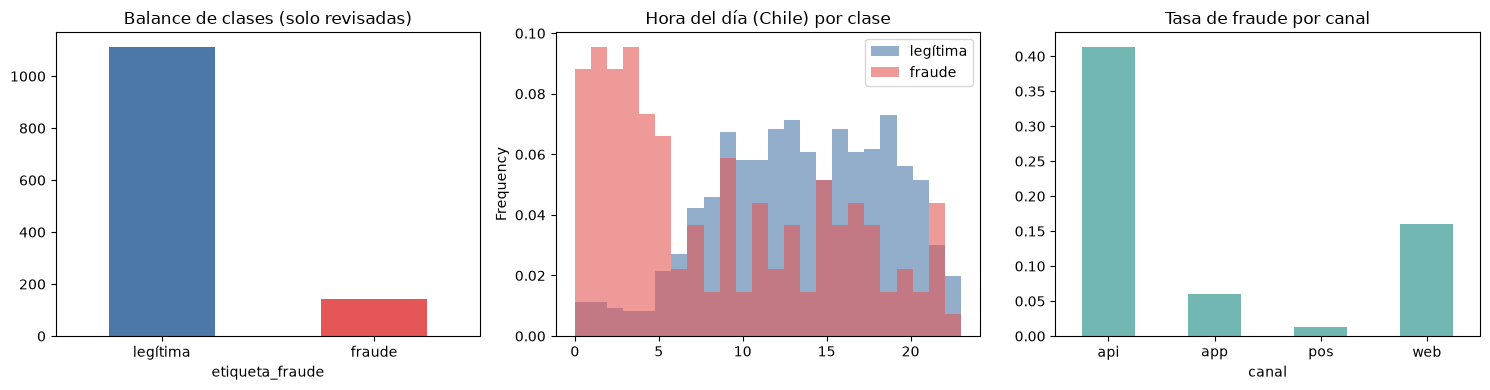

Tasa de fraude entre las revisadas: 11.3%  |  en todo el tráfico: 0.50%


In [ ]:
etiq = base[base["etiqueta_fraude"].notna()]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

etiq["etiqueta_fraude"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"])
ax[0].set_title("Balance de clases (solo revisadas)"); ax[0].set_xticklabels(["legítima", "fraude"], rotation=0)

for clase, color in [(0, "#4C78A8"), (1, "#E45756")]:
    etiq.loc[etiq.etiqueta_fraude == clase, "ts_chile"].dt.hour.plot.hist(ax=ax[1], bins=24, alpha=.6, color=color, density=True)
ax[1].set_title("Hora del día (Chile) por clase"); ax[1].legend(["legítima", "fraude"])

etiq.groupby("canal")["etiqueta_fraude"].mean().plot.bar(ax=ax[2], color="#72B7B2")
ax[2].set_title("Tasa de fraude por canal"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(f"Tasa de fraude entre las revisadas: {etiq.etiqueta_fraude.mean():.1%}  |  en todo el tráfico: {(base.etiqueta_fraude == 1).sum() / len(base):.2%}")

## 4 · Variables de entrada y separación en tres conjuntos

Cada variable sale de una columna ya tratada. **Quedan fuera** a propósito:

| Columna | Por qué no entra |
|---|---|
| `revisado_por_analista`, `motivo_bloqueo` | Fuga de información: solo existen después de revisar la transacción. |
| `resultado_autorizacion` | Es el resultado del motor actual; Randuin decide *antes* de autorizar. |
| `tarjeta_enmascarada`, `ip` | Dato personal (RNF5, 8.3). De la IP solo se conserva si era válida. |
| `latitud`, `longitud` | Solo se conserva si la coordenada era válida. |
| `transaccion_id`, `usuario_id`, `dispositivo_id`, `comercio_id` | Identificadores: el modelo memorizaría casos en vez de aprender patrones. |

In [ ]:
base["hora_chile"]  = base["ts_chile"].dt.hour
base["dia_semana"]  = base["ts_chile"].dt.dayofweek
base["es_noche"]    = base["hora_chile"].isin([0, 1, 2, 3, 4, 5]).astype(int)
base["log_monto"]   = np.log1p(base["monto_clp"].abs())
base["dias_desde_primera_vez_disp"] = (base["ts_utc"] - base["primera_vez"]).dt.total_seconds() / 86400

# ¿el país de la transacción coincide con el del usuario / el del dispositivo?
def distinto(a, b):
    r = (a != b).astype("float")
    return r.where(a.notna() & b.notna())
base["pais_tx_distinto_usuario"]     = distinto(base["pais_transaccion"], base["pais_usuario"])
base["pais_tx_distinto_dispositivo"] = distinto(base["pais_transaccion"], base["pais_dispositivo"])

VARS_NUM = [
    "monto_clp", "log_monto", "hora_chile", "dia_semana", "es_noche", "intentos_previos_1h",
    "nivel_kyc", "verificado", "telefono_verificado", "edad_cuenta_dias", "transacciones_previas",
    "usuarios_distintos", "emulador", "dias_desde_primera_vez_disp",
    "pais_tx_distinto_usuario", "pais_tx_distinto_dispositivo",
    "email_desechable", "so_inconsistente", "dispositivo_lista_negra", "comercio_lista_negra",
    "moneda_inferida", "monto_negativo", "coord_valida", "ip_valida", "usuario_sin_registro", "sin_dispositivo",
]
VARS_CAT = ["canal", "mcc", "pais_transaccion", "segmento", "tipo_dispositivo"]
VARIABLES = VARS_CAT + VARS_NUM

for c in VARS_NUM:
    base[c] = pd.to_numeric(base[c], errors="coerce").astype("float64")
for c in VARS_CAT:
    base[c] = base[c].astype("object").where(base[c].notna(), np.nan)

VARIABLES_NUMERICAS, VARIABLES_CATEGORICAS = VARS_NUM, VARS_CAT
OBJETIVO = "etiqueta_fraude"

pd.DataFrame({"variable": VARIABLES,
              "tipo": ["categórica"] * len(VARS_CAT) + ["numérica"] * len(VARS_NUM),
              "nulos": [int(base[c].isna().sum()) for c in VARIABLES]})

,variable,tipo,nulos
0,canal,categórica,0
1,mcc,categórica,0
2,pais_transaccion,categórica,0
3,segmento,categórica,608
4,tipo_dispositivo,categórica,2526
5,monto_clp,numérica,45
6,log_monto,numérica,45
7,hora_chile,numérica,0
8,dia_semana,numérica,0
9,es_noche,numérica,0


### Tres conjuntos que no se mezclan

| Conjunto | % | Se parece a… | Para qué lo usamos |
|---|---|---|---|
| **Entrenamiento** | 60 % | La guía de ejercicios | El modelo **aprende** aquí |
| **Validación** | 15 % | Los ensayos | Nosotros **decidimos** aquí: umbral, número de épocas, tamaño de la red |
| **Prueba** | 25 % | El examen final | Se **informa** la nota. Se mira **una sola vez**, al final |

**Diferencia con un reparto aleatorio:** las filas se **ordenan por fecha** y se corta en orden (lo más antiguo entrena, lo siguiente valida, lo más reciente prueba). Así se simula lo que pasa en producción: el modelo siempre predice transacciones *posteriores* a las que vio.

**Solo se usan las filas con etiqueta** (las que un analista revisó). Cada transacción sin etiqueta se excluye porque no sabemos si era fraude.

In [ ]:
etiquetadas = base[base["etiqueta_fraude"].notna()].sort_values("ts_utc").reset_index(drop=True)
n = len(etiquetadas)
i_val, i_test = int(n * 0.60), int(n * 0.75)
train, val, test = etiquetadas.iloc[:i_val], etiquetadas.iloc[i_val:i_test], etiquetadas.iloc[i_test:]

X_train, y_train = train[VARIABLES], train[OBJETIVO].astype(int)
X_val,   y_val   = val[VARIABLES],   val[OBJETIVO].astype(int)
X_test,  y_test  = test[VARIABLES],  test[OBJETIVO].astype(int)

# Monto en USD de cada fila: lo necesita el costo de un fraude no detectado.
# Los montos vacíos se rellenan con la mediana de ENTRENAMIENTO (no se mira prueba).
mediana_monto = train["monto_clp"].abs().median()
def monto_usd(df):
    return (df["monto_clp"].abs().fillna(mediana_monto) / USD_CLP).to_numpy()
M_train, M_val, M_test = monto_usd(train), monto_usd(val), monto_usd(test)

for nombre, (d_, ys) in {"Entrenamiento": (train, y_train), "Validación": (val, y_val), "Prueba": (test, y_test)}.items():
    print(f"{nombre:<14} {len(d_):>5,} filas ({ys.mean():.1%} fraudes, {int(ys.sum())} casos) · "
          f"{d_['ts_utc'].min().date()} → {d_['ts_utc'].max().date()}")

Entrenamiento    753 filas (10.0% fraudes, 75 casos) · 2023-08-01 → 2025-06-05
Validación       188 filas (11.2% fraudes, 21 casos) · 2025-06-07 → 2025-11-20
Prueba           314 filas (14.6% fraudes, 46 casos) · 2025-11-22 → 2026-08-01


## 5 · La línea base «tonta»

Antes de cualquier modelo real, se mide lo que logra **no hacer nada**. Todo modelo tiene que ganarle a esto.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

tonto = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_tonto = tonto.predict(X_test)
print(f"Exactitud (accuracy): {accuracy_score(y_test, pred_tonto):.1%}")
print(f"Fraudes detectados (recall): {recall_score(y_test, pred_tonto):.1%}")

Exactitud (accuracy): 85.4%
Fraudes detectados (recall): 0.0%


**Más de 80 % de exactitud sin detectar ni un fraude** (y en todo el tráfico, donde el fraude es 0,5 %, sería de 99,5 %). Por eso la exactitud no sirve como métrica principal en fraude.

Vamos a medir con lo que le importa al negocio: **cuánto dinero se pierde** entre fraudes que pasan y alertas que hay que revisar.

In [ ]:
def costo_operacional(y_real, y_pred, monto_usd) -> float:
    """Costo en USD = montos de los fraudes NO detectados + costo de revisar cada alerta (verdadera o falsa)."""
    y_real, y_pred, monto = np.asarray(y_real), np.asarray(y_pred), np.asarray(monto_usd)
    fraudes_no_detectados = (y_pred == 0) & (y_real == 1)
    alertas = int((y_pred == 1).sum())
    return float(monto[fraudes_no_detectados].sum() + alertas * COSTO_REVISION_USD)

print(f"Sin modelo (aprobar todo):     USD {costo_operacional(y_test, np.zeros_like(y_test), M_test):>10,.0f}")
print(f"Revisar todas las operaciones: USD {costo_operacional(y_test, np.ones_like(y_test), M_test):>10,.0f}")

Sin modelo (aprobar todo):     USD      2,721
Revisar todas las operaciones: USD      1,570


## 6 · Línea base clásica: regresión logística (scikit-learn)

Antes de la red neuronal, un modelo clásico y rápido. Sirve de **vara**: si la red no le gana, no se justifica su complejidad.

El **preprocesamiento** (imputar nulos, escalar, one-hot) se define en una función porque lo vamos a reutilizar con la red.

```
 transacción ──► [ imputar nulos → escalar ]  numéricas    ──►  vector de N números  ──►  modelo  ──►  probabilidad
                 [ one-hot ]                  categóricas
```

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador() -> ColumnTransformer:
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),            # nulo → mediana de entrenamiento
            ("escalar", StandardScaler()),
        ]), VARIABLES_NUMERICAS),
        ("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="constant", fill_value="desconocido")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), VARIABLES_CATEGORICAS),
    ])

modelo_base = Pipeline([
    ("prep", construir_preprocesador()),
    ("clf", LogisticRegression(max_iter=1000)),
])
modelo_base.fit(X_train, y_train)
modelo_base

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31,)","['canal','mcc','pais_transaccion',...,'ip_valida','usuario_sin_registro', 'sin_dispositivo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrou

## 7 · Evaluación

              precision    recall  f1-score   support

    legítima      0.982     0.996     0.989       268
      fraude      0.976     0.891     0.932        46

    accuracy                          0.981       314
   macro avg      0.979     0.944     0.960       314
weighted avg      0.981     0.981     0.981       314

ROC-AUC: 0.990  |  PR-AUC: 0.965
Costo operacional (umbral 0,5): USD 410


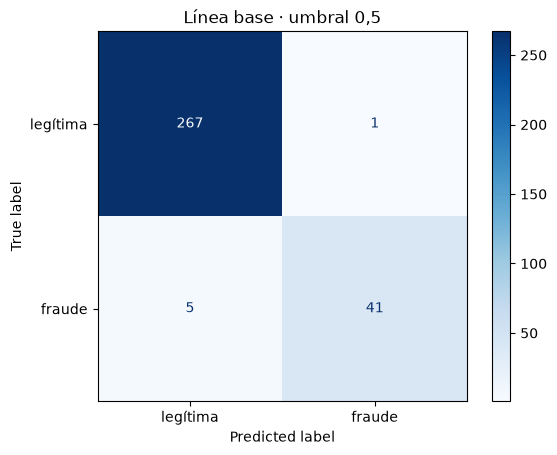

In [ ]:
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             classification_report, roc_auc_score)

prob_test = modelo_base.predict_proba(X_test)[:, 1]     # probabilidad de fraude
pred_test = (prob_test >= 0.5).astype(int)               # umbral por defecto

print(classification_report(y_test, pred_test, target_names=["legítima", "fraude"], digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, prob_test):.3f}  |  PR-AUC: {average_precision_score(y_test, prob_test):.3f}")
print(f"Costo operacional (umbral 0,5): USD {costo_operacional(y_test, pred_test, M_test):,.0f}")

ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["legítima", "fraude"], cmap="Blues")
plt.title("Línea base · umbral 0,5"); plt.show()

**Cómo leerlo:**
- **Recall de «fraude»**: de los fraudes reales, ¿cuántos detectó? Cada uno que se escapa cuesta su monto completo.
- **Precision de «fraude»**: de las alertas, ¿cuántas eran fraude de verdad? Cada alerta falsa es un cliente legítimo molestado y una revisión pagada de más.
- **ROC-AUC / PR-AUC**: qué tan bien *ordena* el modelo por riesgo, independiente del umbral. PR-AUC es más honesta con clases desbalanceadas.

### El umbral es una decisión de negocio, no del algoritmo
El `0,5` es arbitrario. Como un fraude no detectado cuesta su monto completo y una revisión cuesta USD 5, conviene alertar con probabilidades distintas a 0,5. Veamos cómo cambia el costo **en validación** (prueba no se toca para elegir):

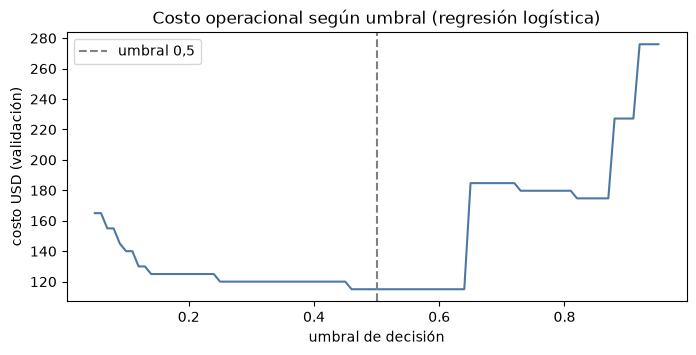

In [ ]:
umbrales = np.arange(0.05, 0.96, 0.01)
prob_val_lr = modelo_base.predict_proba(X_val)[:, 1]
costos = [costo_operacional(y_val, (prob_val_lr >= u).astype(int), M_val) for u in umbrales]

plt.figure(figsize=(8, 3.5))
plt.plot(umbrales, costos, color="#4C78A8")
plt.axvline(0.5, ls="--", color="gray", label="umbral 0,5")
plt.xlabel("umbral de decisión"); plt.ylabel("costo USD (validación)")
plt.title("Costo operacional según umbral (regresión logística)")
plt.legend(); plt.show()

> Cada modelo queda registrado en una **tabla de posiciones**, con el umbral elegido en **validación** y el costo informado en **prueba**.

In [ ]:
tabla = []

def mejor_umbral(y_real, prob, monto) -> float:
    candidatos = np.arange(0.02, 0.96, 0.01)
    costos = [costo_operacional(y_real, (prob >= u).astype(int), monto) for u in candidatos]
    return float(candidatos[int(np.argmin(costos))])

def registrar(nombre: str, prob_val, prob_test) -> float:
    umbral = mejor_umbral(y_val, prob_val, M_val)             # ← decidido SIN mirar prueba
    pred = (prob_test >= umbral).astype(int)
    tabla.append({
        "modelo": nombre, "umbral": round(umbral, 2),
        "costo_usd": round(costo_operacional(y_test, pred, M_test)),
        "recall": round(recall_score(y_test, pred), 3),
        "alertas": int(pred.sum()),
        "roc_auc": round(roc_auc_score(y_test, prob_test), 3),
        "pr_auc": round(average_precision_score(y_test, prob_test), 3),
    })
    display(pd.DataFrame(tabla).sort_values("costo_usd").reset_index(drop=True))
    return umbral

umbral_lr = registrar("0 · LogReg (scikit-learn)", prob_val_lr, prob_test)

,modelo,umbral,costo_usd,recall,alertas,roc_auc,pr_auc
0,0 · LogReg (scikit-learn),0.46,415,0.891,43,0.99,0.965


## 8 · La red neuronal (TensorFlow / Keras)

La red no sabe de nulos ni de textos como `"app"`: recibe un **vector de números**. Por eso separamos el trabajo en dos piezas que viajan juntas a la imagen:

```
 JSON ──► preprocesador.joblib ──► vector de N números ──► modelo.onnx ──► probabilidad
          (scikit-learn)                                    (red de Keras, ejecutada por onnxruntime)
          imputar · escalar · one-hot
```

Primero ajustamos el preprocesador **solo con entrenamiento** y transformamos los tres conjuntos a matrices `float32` (el tipo que esperan las redes).

In [ ]:
prep = construir_preprocesador().fit(X_train)

A_train = prep.transform(X_train).astype(np.float32)
A_val   = prep.transform(X_val).astype(np.float32)
A_test  = prep.transform(X_test).astype(np.float32)

print("Forma de A_train:", A_train.shape)
print("Columnas que ve la red:", list(prep.get_feature_names_out())[:12], "...")

Forma de A_train: (753, 60)
Columnas que ve la red: ['num__monto_clp', 'num__log_monto', 'num__hora_chile', 'num__dia_semana', 'num__es_noche', 'num__intentos_previos_1h', 'num__nivel_kyc', 'num__verificado', 'num__telefono_verificado', 'num__edad_cuenta_dias', 'num__transacciones_previas', 'num__usuarios_distintos'] ...


Una red **MLP** (perceptrón multicapa) con dos capas ocultas. Lo importante del código:
- `Dense(n, activation="relu")` + `Dropout`: las capas ocultas, y una salida de 1 neurona con `sigmoid` (probabilidad entre 0 y 1).
- `class_weight`: **pesa más los fraudes**, que son pocos (aquí ~11 % de las filas etiquetadas).
- Entrenamiento por **mini-lotes** de 64 filas con Adam, de a 10 épocas.
- Cada 10 épocas se muestra la **PR-AUC en validación** para ver si sigue aprendiendo o empieza a sobreajustar.

In [ ]:
def entrenar_red_tensorflow(capas=(64, 32), dropout=0.2, epocas=60, lr=1e-3, peso_clase=True):
    import os
    os.environ.setdefault("KERAS_BACKEND", "tensorflow")
    import keras
    import tensorflow as tf

    keras.utils.set_random_seed(SEMILLA)
    red = keras.Sequential([keras.Input(shape=(A_train.shape[1],))])
    for n in capas:
        red.add(keras.layers.Dense(n, activation="relu"))
        red.add(keras.layers.Dropout(dropout))
    red.add(keras.layers.Dense(1, activation="sigmoid"))          # salida: probabilidad
    red.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy")

    peso = float((y_train == 0).sum() / (y_train == 1).sum()) if peso_clase else 1.0

    def predecir(A):
        return red.predict(A, verbose=0).ravel()

    hechas = 0
    while hechas < epocas:
        tramo = min(10, epocas - hechas)
        red.fit(A_train, y_train.to_numpy(), epochs=tramo, batch_size=64,
                class_weight={0: 1.0, 1: peso}, verbose=0)
        hechas += tramo
        print(f"época {hechas:>3} · PR-AUC validación {average_precision_score(y_val, predecir(A_val)):.3f}")

    def exportar_onnx(ruta):
        try:
            red.export(str(ruta), format="onnx")                  # usa tf2onnx por debajo
        except Exception as error:                                # versiones de Keras sin export nativo a ONNX
            print("export nativo no disponible, uso tf2onnx:", type(error).__name__)
            import subprocess, sys, tempfile
            with tempfile.TemporaryDirectory() as tmp:            # vía alternativa: SavedModel -> ONNX
                red.export(tmp)                                   # formato por defecto: SavedModel
                subprocess.run([sys.executable, "-m", "tf2onnx.convert", "--saved-model", tmp,
                                "--output", str(ruta), "--opset", "17"], check=True)

    return {"predecir": predecir, "exportar_onnx": exportar_onnx, "framework": f"tensorflow {tf.__version__}"}

In [ ]:
entrenar_red = entrenar_red_tensorflow

t0 = time.perf_counter()
red = entrenar_red(capas=(64, 32), dropout=0.2, epocas=60, lr=1e-3)
print(f"Entrenada con {red['framework']} en {time.perf_counter() - t0:.1f} s")

umbral_red = registrar("1 · Red 64-32 (TensorFlow)", red["predecir"](A_val), red["predecir"](A_test))

época  10 · PR-AUC validación 0.983
época  20 · PR-AUC validación 0.996
época  30 · PR-AUC validación 0.996
época  40 · PR-AUC validación 0.996
época  50 · PR-AUC validación 0.998
época  60 · PR-AUC validación 1.000
Entrenada con tensorflow 2.22.0-rc0 en 17.5 s


,modelo,umbral,costo_usd,recall,alertas,roc_auc,pr_auc
0,0 · LogReg (scikit-learn),0.46,415,0.891,43,0.990,0.965
1,1 · Red 64-32 (TensorFlow),0.85,478,0.848,40,0.982,0.958


## 9 · Exportar a ONNX y verificar

Se exportan **tres archivos** a la carpeta `servicio-ia/model/`:

| Archivo | Contenido | Quién lo usa en la API |
|---|---|---|
| `preprocesador.joblib` | Imputar, escalar y one-hot (scikit-learn) | Transforma el JSON en el vector de números |
| `modelo.onnx` | La red entrenada (pesos + grafo) | `onnxruntime` calcula la probabilidad |
| `metadata.json` | Versión, framework, umbral, métricas, versión de scikit-learn, resumen de la limpieza | `/predict` responde la versión; `/health` la expone |

Antes de dar por bueno el ONNX lo **verificamos**: `onnxruntime` tiene que dar las mismas probabilidades que la red original.

In [ ]:
import onnxruntime as ort

def exportar(red, version: str, umbral: float, descripcion: str) -> dict:
    RUTA_MODELO.mkdir(parents=True, exist_ok=True)
    for viejo in ["modelo.joblib", "modelo.onnx", "preprocesador.joblib"]:
        (RUTA_MODELO / viejo).unlink(missing_ok=True)

    joblib.dump(prep, RUTA_MODELO / "preprocesador.joblib")
    red["exportar_onnx"](RUTA_MODELO / "modelo.onnx")

    # Verificación: onnxruntime (lo que usará la API) vs. la red original
    sesion = ort.InferenceSession(str(RUTA_MODELO / "modelo.onnx"), providers=["CPUExecutionProvider"])
    p_onnx = sesion.run(None, {sesion.get_inputs()[0].name: A_test})[0].ravel()
    diferencia = float(np.abs(p_onnx - red["predecir"](A_test)).max())
    assert diferencia < 1e-4, f"El ONNX no reproduce a la red (diferencia {diferencia})"

    pred = (p_onnx >= umbral).astype(int)
    metadata = {
        "nombre": "fraude-randuin",
        "version": version,
        "formato": "onnx",
        "framework": red["framework"],
        "descripcion": descripcion,
        "entrenado_en": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "variables_numericas": VARIABLES_NUMERICAS,
        "variables_categoricas": VARIABLES_CATEGORICAS,
        "umbral": round(float(umbral), 4),
        "filas_entrenamiento": int(len(X_train)),
        "metricas_prueba": {
            "roc_auc": round(roc_auc_score(y_test, p_onnx), 4),
            "pr_auc": round(average_precision_score(y_test, p_onnx), 4),
            "recall": round(recall_score(y_test, pred), 4),
            "precision": round(float(((pred == 1) & (y_test.to_numpy() == 1)).sum() / max(int(pred.sum()), 1)), 4),
            "falsos_positivos": int(((pred == 1) & (y_test.to_numpy() == 0)).sum()),
            "costo_usd": round(costo_operacional(y_test, pred, M_test)),
        },
        "limpieza": registro_limpieza,
    }
    (RUTA_MODELO / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

    print(f"✔ ONNX verificado: diferencia máxima con la red original {diferencia:.1e}")
    for f in sorted(RUTA_MODELO.iterdir()):
        print(f"   {f.name:<22} {f.stat().st_size / 1024:>6.1f} KB")
    print(f"✔ Exportado {version} ({red['framework']})")
    return metadata

meta = exportar(red, version=f"1.0.0-{FRAMEWORK}", umbral=umbral_red,
                descripcion="MLP 64-32, dropout 0.2, 60 epocas")
meta["metricas_prueba"]



Saved artifact at 'c:\Users\maxer\OneDrive\Desktop\randuin\servicio-ia\model\modelo.onnx'.
✔ ONNX verificado: diferencia máxima con la red original 7.6e-08
   metadata.json             1.6 KB
   modelo.onnx              25.0 KB
   preprocesador.joblib      6.6 KB
✔ Exportado 1.0.0-tensorflow (tensorflow 2.22.0-rc0)


{'roc_auc': 0.9825,
 'pr_auc': 0.9584,
 'recall': 0.8478,
 'precision': 0.975,
 'falsos_positivos': 1,
 'costo_usd': 478}

### Simular lo que hará la API
La API no tiene TensorFlow: solo `onnxruntime`. Probemos el artefacto **exactamente** como lo usará: cargar los dos archivos desde disco y predecir un JSON con campos en `null`.

> Ojo para el microservicio: el JSON trae `null` (Python `None`); hay que convertirlo a `NaN` antes de transformar, porque el imputador reconoce `NaN`.

In [ ]:
prep_api = joblib.load(RUTA_MODELO / "preprocesador.joblib")
sesion_api = ort.InferenceSession(str(RUTA_MODELO / "modelo.onnx"), providers=["CPUExecutionProvider"])
umbral_api = json.loads((RUTA_MODELO / "metadata.json").read_text())["umbral"]

# ← esto es lo que llegará en el body de POST /predict (los vacíos viajan como null)
fila = X_test.iloc[0]
transaccion = {c: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v)) for c, v in fila.items()}
transaccion["usuarios_distintos"] = None            # forzamos un nulo para probar la imputación
print(json.dumps(transaccion, ensure_ascii=False)[:300], "...")

t0 = time.perf_counter()
entrada = pd.DataFrame([transaccion], columns=VARIABLES)
entrada = entrada.astype(object).where(entrada.notna(), np.nan)          # null → NaN
x = prep_api.transform(entrada).astype(np.float32)
p = float(sesion_api.run(None, {sesion_api.get_inputs()[0].name: x})[0].ravel()[0])
latencia_ms = (time.perf_counter() - t0) * 1000
print(f"\nProbabilidad de fraude: {p:.1%}  →  {'ALERTA (revisar/bloquear)' if p >= umbral_api else 'aprobar'}")
print(f"Latencia de inferencia (preprocesar + red): {latencia_ms:.2f} ms")

{"canal": "app", "mcc": "7995", "pais_transaccion": "CL", "segmento": null, "tipo_dispositivo": "android", "monto_clp": 11587.0, "log_monto": 9.35772535888924, "hora_chile": 6.0, "dia_semana": 5.0, "es_noche": 0.0, "intentos_previos_1h": 2.0, "nivel_kyc": null, "verificado": null, "telefono_verifica ...

Probabilidad de fraude: 0.3%  →  aprobar
Latencia de inferencia (preprocesar + red): 6.88 ms
